In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import yfinance as yf
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt 
import matplotlib.dates as mdates


In [2]:
data = pd.read_csv("../data/processed/merged_data.csv")

print(data.describe())

        log_return         NFCI          EPU          GPR    Yield_10Y  \
count  4022.000000  4022.000000  4022.000000  4022.000000  4020.000000   
mean      0.000449    -0.464710   172.616111   102.083369     2.603451   
std       0.010943     0.178121    91.976970    31.577164     1.003960   
min      -0.127652    -0.792000    64.000000    58.420769     0.499000   
25%      -0.003808    -0.580000   116.000000    80.725357     1.853000   
50%       0.000702    -0.499000   150.000000    92.596016     2.457500   
75%       0.005676    -0.365000   197.000000   115.303448     3.333250   
max       0.090895     0.306000   725.000000   318.954926     4.988000   

          Yield_2Y  Spread_2Y10Y          VIX         EFFR      CPI_YoY  \
count  4020.000000   4020.000000  4022.000000  4022.000000  4022.000000   
mean      1.370234     -1.233217    18.413332     1.413289     2.593714   
std       1.803998      1.220770     6.874718     1.809908     1.889649   
min      -0.105000     -3.834000 

In [3]:
print("Kurtosis:")
print(data[["log_return", "NFCI", "EPU", "GPR", "Yield_10Y", "Yield_2Y", "Spread_2Y10Y", "VIX", "EFFR", "CPI_YoY", "Unemployment"]].kurt())
print("\nSkewness:")
print(data[["log_return", "NFCI", "EPU", "GPR", "Yield_10Y", "Yield_2Y", "Spread_2Y10Y", "VIX", "EFFR", "CPI_YoY", "Unemployment"]].skew())
print("Jarque_Bera:")
print(stats.jarque_bera(data["log_return"].dropna()))

Kurtosis:
log_return      13.574027
NFCI             1.058593
EPU              9.567630
GPR             12.048211
Yield_10Y       -0.656495
Yield_2Y        -0.306141
Spread_2Y10Y    -0.534432
VIX             11.042485
EFFR            -0.226518
CPI_YoY          2.513245
Unemployment     0.832781
dtype: float64

Skewness:
log_return     -0.615225
NFCI            0.790978
EPU             2.639922
GPR             2.495249
Yield_10Y       0.284288
Yield_2Y        1.108949
Spread_2Y10Y    0.300346
VIX             2.393042
EFFR            1.144451
CPI_YoY         1.620829
Unemployment    1.110652
dtype: float64
Jarque_Bera:
SignificanceResult(statistic=np.float64(31047.99536295866), pvalue=np.float64(0.0))


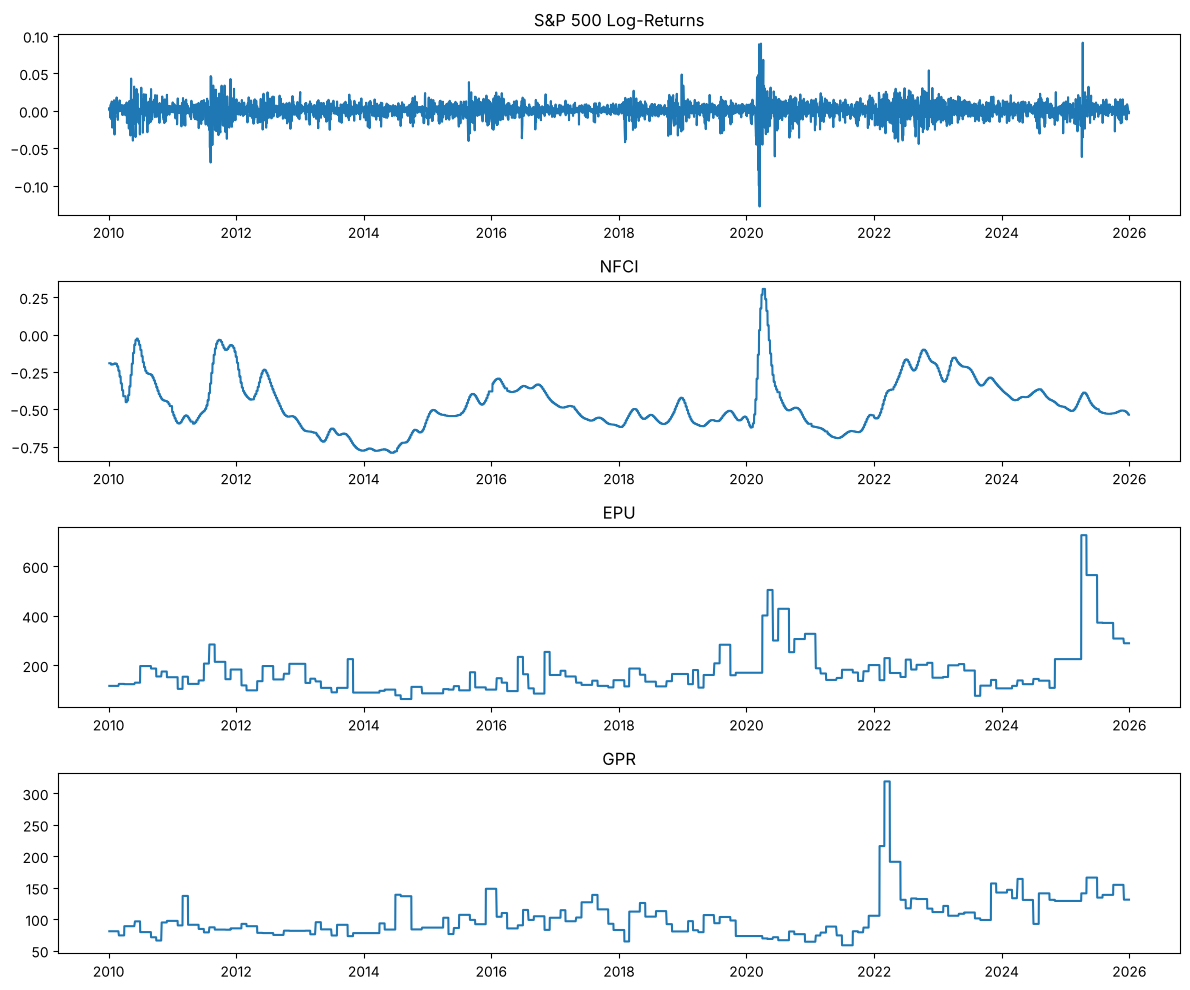

In [4]:
# forcer l'index en datetime si ce n'est pas déjà fait
data_plot = data.copy()
if not isinstance(data_plot.index, pd.DatetimeIndex):
    data_plot.index = pd.to_datetime(data_plot["Date"])

fig, axes = plt.subplots(4, 1, figsize=(12, 10))

axes[0].plot(data_plot.index, data_plot["log_return"])
axes[0].set_title("S&P 500 Log-Returns")

axes[1].plot(data_plot.index, data_plot["NFCI"])
axes[1].set_title("NFCI")

axes[2].plot(data_plot.index, data_plot["EPU"])
axes[2].set_title("EPU")

axes[3].plot(data_plot.index, data_plot["GPR"])
axes[3].set_title("GPR")

for ax in axes:
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    ax.xaxis.set_major_locator(mdates.YearLocator(2))

plt.tight_layout()
plt.savefig("../results/timeseries_overview.png", dpi=150, bbox_inches="tight")
plt.show()

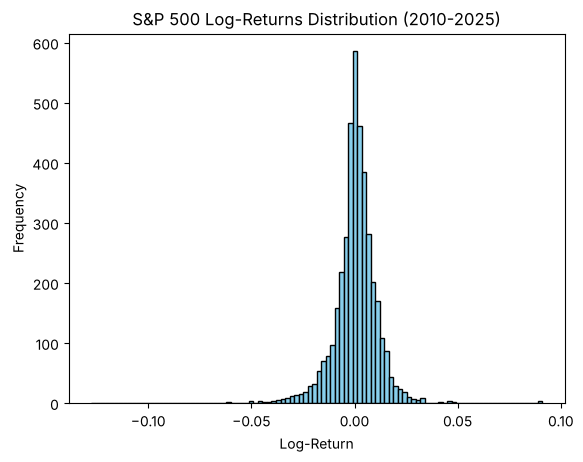

In [5]:
plt.hist(data["log_return"], bins=100, color='skyblue', edgecolor='black')
plt.xlabel('Log-Return')
plt.ylabel('Frequency')
plt.title('S&P 500 Log-Returns Distribution (2010-2025)')
plt.savefig("../results/histogram_log_returns.png", dpi=150, bbox_inches="tight")
plt.show()